# Распознавание поддельных вакансий

**Данные:** *Real or Fake: Fake Job Posting Prediction*, файл `fake_job_postings.csv`.

- `numpy` - матричные операции
- `matplotlib` - научная графика
- `pandas` - таблицы (DataFrame) для анализа данных
- `scikit-learn` - алгоритмы машинного обучения

## 0. Постановка задачи

В датасете 17 880 вакансий, опубликованных на сайте по поиску работы. Каждая вакансия размечена как настоящая
(`fraudulent = 0`) или мошенническая (`fraudulent = 1`).

**Задача:** по описанию вакансии (тип занятости, требования к опыту и образованию, наличие логотипа компании,
тексты описания и т.д.) определить, является ли она мошеннической. Это задача **бинарной классификации**.

Особенность задачи **классы несбалансированы**: мошеннических вакансий около 5%. Поэтому кроме доли ошибок
будем смотреть на матрицу рассогласования — сколько мошеннических вакансий классификатор действительно находит.

**Признаки:**

| Признак | Описание |
|---|---|
| `job_id` | номер вакансии |
| `title` | название вакансии (текст) |
| `location` | место работы: «страна, регион, город» |
| `department` | отдел компании |
| `salary_range` | вилка зарплаты |
| `company_profile` | описание компании (текст) |
| `description` | описание вакансии (текст) |
| `requirements` | требования к кандидату (текст) |
| `benefits` | что предлагает работодатель (текст) |
| `telecommuting` | удалённая работа (0/1) |
| `has_company_logo` | есть логотип компании (0/1) |
| `has_questions` | есть вопросы для отбора кандидатов (0/1) |
| `employment_type` | тип занятости (Full-time, Part-time, ...) |
| `required_experience` | требуемый опыт |
| `required_education` | требуемое образование |
| `industry` | отрасль |
| `function` | направление работы |
| `fraudulent` | целевая переменная: 1 - мошенническая вакансия |

## 1. Чтение данных

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [43]:
data = pd.read_csv('fake_job_postings.csv')
print(data.shape)

(17880, 18)


In [44]:
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [45]:
print(data.columns)

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')


In [46]:
data['fraudulent'].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

Посмотрим, сколько разных значений в некоторых столбцах:

In [47]:
data[['location', 'department', 'salary_range', 'industry', 'function']].nunique()

location        3105
department      1337
salary_range     874
industry         131
function          37
dtype: int64

**Какие столбцы используем:**

- `job_id` - просто номер вакансии -> удаляем.
- `location`, `department`, `salary_range`, `industry` - слишком много разных значений (а у `department`
  и `salary_range` ещё и большая часть значений пропущена) -> удаляем их.
- `title`, `company_profile`, `description`, `requirements`, `benefits` - тексты. Метод ближайших соседей не умеет
  работать с текстом напрямую, поэтому заменим каждый текст его длиной.
  Если текст отсутствует, его длина равна 0.

In [48]:
data = data.drop(['job_id', 'location', 'department', 'salary_range', 'industry'], axis = 1)

text_columns = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for c in text_columns:
    data['len_' + c] = data[c].fillna('').str.len()
data = data.drop(text_columns, axis = 1)

data.head()

,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,function,fraudulent,len_title,len_company_profile,len_description,len_requirements,len_benefits
0,0,1,0,Other,Internship,NaN,Marketing,0,16,885,905,852,0
1,0,1,0,Full-time,Not Applicable,NaN,Customer Service,0,41,1286,2077,1433,1292
2,0,1,0,NaN,NaN,NaN,NaN,0,39,879,355,1363,0
3,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Sales,0,33,614,2600,1429,782
4,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Health Care Provider,0,19,1628,1520,757,21


In [49]:
categorical_columns = ['employment_type', 'required_experience', 'required_education', 'function']
binary_columns      = ['telecommuting', 'has_company_logo', 'has_questions']
numerical_columns   = ['len_' + c for c in text_columns]
print(data.shape)

(17880, 13)


## 2. Разбиение на обучающую и тестовую выборки

Отводим на тестовую выборку 30% данных. Параметр `stratify` делает так, чтобы доля мошеннических
вакансий в обеих выборках была одинаковой.

Разбиваем номера строк. Все величины, которые нужны для обработки данных (квантили, самые частые значения,
средние и стандартные отклонения), дальше считаем только по обучающей выборке.

In [50]:
from sklearn.model_selection import train_test_split
train_index, test_index = train_test_split(data.index, test_size = 0.3, stratify = data['fraudulent'],
                                           random_state = 42)
print(len(train_index), len(test_index))

data_train = data.loc[train_index]

12516 5364


## 3. Визуализация и основные характеристики

Характеристики считаем по обучающей выборке.

In [51]:
data_train.describe()

,telecommuting,has_company_logo,has_questions,fraudulent,len_title,len_company_profile,len_description,len_requirements,len_benefits
count,12516.000000,12516.000000,12516.000000,12516.000000,12516.000000,12516.000000,12516.000000,12516.000000,12516.000000
mean,0.041627,0.794263,0.492649,0.048418,28.568153,617.157478,1212.759668,587.996085,206.000879
std,0.199743,0.404255,0.499966,0.214656,13.845252,565.057760,896.997293,610.486617,331.421332
min,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,19.000000,134.000000,602.750000,149.000000,0.000000
50%,0.000000,1.000000,0.000000,0.000000,26.000000,561.000000,1009.000000,466.500000,42.000000
75%,0.000000,1.000000,1.000000,0.000000,35.000000,879.000000,1583.000000,818.000000,288.000000
max,1.000000,1.000000,1.000000,1.000000,142.000000,5574.000000,14907.000000,10864.000000,4429.000000


In [52]:
data_train[categorical_columns].describe()

,employment_type,required_experience,required_education,function
count,10135,7571,6845,8009
unique,5,7,13,37
top,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology
freq,8150,2635,3594,1228


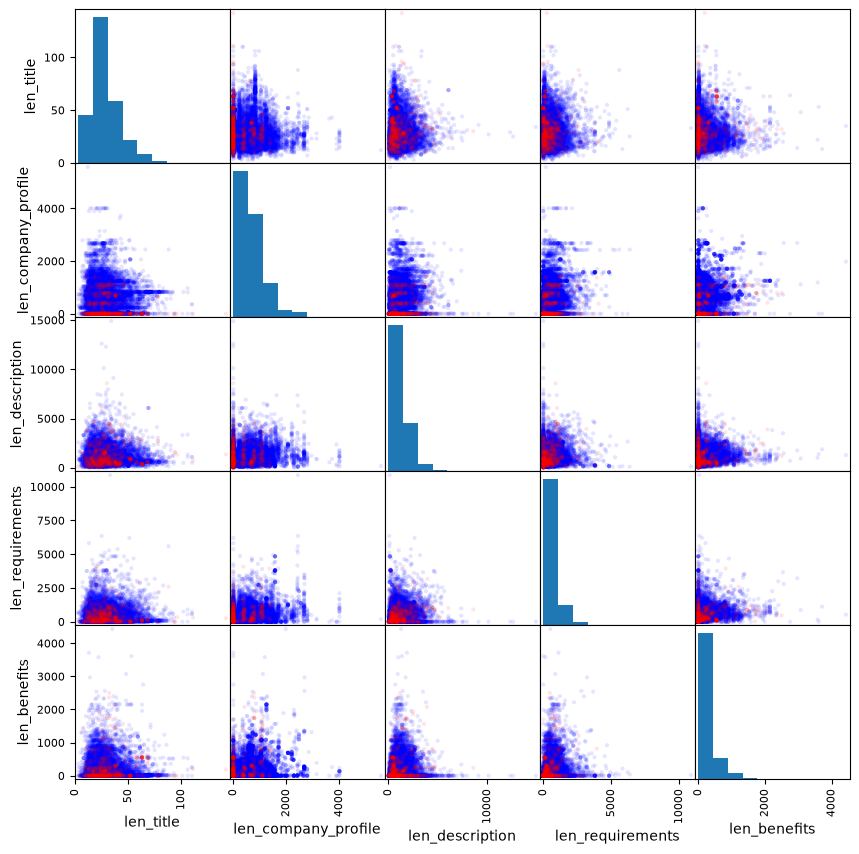

In [53]:
from pandas.plotting import scatter_matrix
data_sorted = data_train.sort_values('fraudulent')
scatter_matrix(data_sorted[numerical_columns], c = data_sorted['fraudulent'].map({0: 'b', 1: 'r'}),
               alpha = .1, figsize = (10, 10))
pass

Синие точки это настоящие вакансии, а красные - мошеннические.

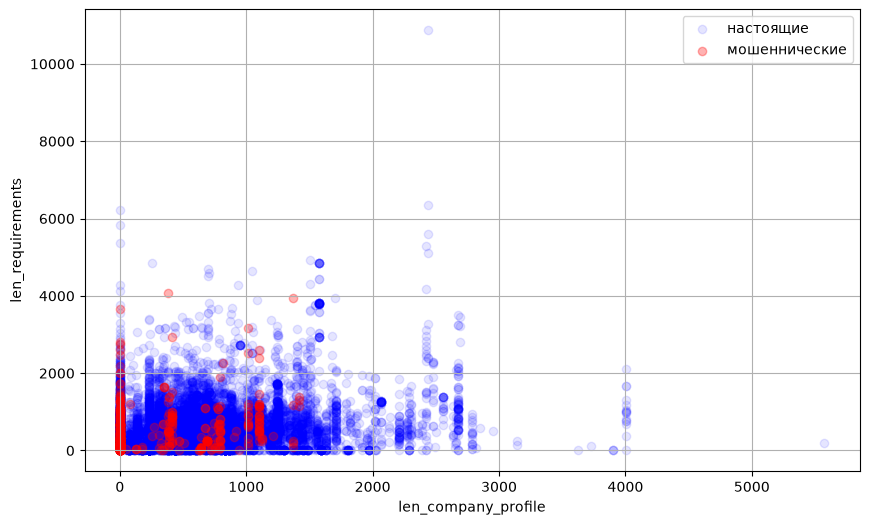

In [54]:
plt.figure(figsize = (10, 6))

plt.scatter(data_train[data_train['fraudulent'] == 0]['len_company_profile'],
            data_train[data_train['fraudulent'] == 0]['len_requirements'],
            alpha = 0.1,
            label = 'настоящие',
            color = 'b')

plt.scatter(data_train[data_train['fraudulent'] == 1]['len_company_profile'],
            data_train[data_train['fraudulent'] == 1]['len_requirements'],
            alpha = 0.3,
            label = 'мошеннические',
            color = 'r')

plt.xlabel('len_company_profile')
plt.ylabel('len_requirements')
plt.legend()
plt.grid()

Корреляционная матрица:

In [55]:
data_train[numerical_columns + binary_columns + ['fraudulent']].corr()

,len_title,len_company_profile,len_description,len_requirements,len_benefits,telecommuting,has_company_logo,has_questions,fraudulent
len_title,1.000000,-0.012787,-0.027464,-0.009778,-0.024749,0.005432,0.003854,0.002491,0.033357
len_company_profile,-0.012787,1.000000,0.125309,0.212493,0.173675,-0.029665,0.460353,0.118156,-0.158114
len_description,-0.027464,0.125309,1.000000,0.089647,0.067617,-0.008478,0.005390,-0.002241,-0.015586
len_requirements,-0.009778,0.212493,0.089647,1.000000,0.152568,0.012269,0.113999,0.032831,-0.054670
len_benefits,-0.024749,0.173675,0.067617,0.152568,1.000000,0.002235,0.153853,0.090360,-0.000899
telecommuting,0.005432,-0.029665,-0.008478,0.012269,0.002235,1.000000,-0.026531,0.015466,0.036851
has_company_logo,0.003854,0.460353,0.005390,0.113999,0.153853,-0.026531,1.000000,0.241780,-0.265491
has_questions,0.002491,0.118156,-0.002241,0.032831,0.090360,0.015466,0.241780,1.000000,-0.096451
fraudulent,0.033357,-0.158114,-0.015586,-0.054670,-0.000899,0.036851,-0.265491,-0.096451,1.000000


Доля мошеннических вакансий в зависимости от значения бинарных признаков:

In [56]:
for c in binary_columns:
    print(data_train.groupby(c)['fraudulent'].mean(), '\n')

telecommuting
0    0.046769
1    0.086372
Name: fraudulent, dtype: float64 

has_company_logo
0    0.160388
1    0.019415
Name: fraudulent, dtype: float64 

has_questions
0    0.068819
1    0.027408
Name: fraudulent, dtype: float64 



**Интерпретация.**

- В обучающей выборке 12 516 вакансий, из них мошеннических 4.8% -> классы сильно несбалансированы.
- Распределения длин текстов несимметричны, с длинным правым хвостом: среднее больше медианы
  (у `len_description` 1213 и 1009 символов), а максимум почти 15 000 символов.
  У `len_company_profile`, `len_requirements`, `len_benefits` много нулей -> это вакансии без соответствующего текста.
- На диаграммах рассеяния мошеннические вакансии скапливаются у левого края по `len_company_profile`,
  то есть у них часто нет описания компании. По остальным длинам классы сильно перемешаны.
- Корреляции признаков с целевой переменной слабые: сильнее всего `has_company_logo` (−0.27),
  `len_company_profile` (−0.16) и `has_questions` (−0.10). Значит, ни один признак в отдельности не позволяет
  отделить мошеннические вакансии -> нужно их сочетание.
- Между собой признаки тоже коррелируют слабо; заметна только связь `len_company_profile` и `has_company_logo`
  (0.46): компании, которые заполнили описание, обычно загружают и логотип.
- По бинарным признакам: без логотипа мошеннических 16.0%, с логотипом 1.9%, без вопросов к кандидату 6.9%
  против 2.7%, при удалённой работе 8.6% против 4.7%.
- В категориальных признаках много пропусков: например, `required_education` указано только у 6 845 вакансий из 12 516.

## 4. Выбросы

Посмотрим на квантили числовых признаков (длин текстов):

In [57]:
data_train[numerical_columns].quantile([0.005, .01, .05, .1, .5, .9, .95, .99, .995])

,len_title,len_company_profile,len_description,len_requirements,len_benefits
0.005,7.0,0.0,81.575,0.000,0.00
0.010,9.0,0.0,102.000,0.000,0.00
0.050,13.0,0.0,244.000,0.000,0.00
0.100,14.0,0.0,354.000,0.000,0.00
0.500,26.0,561.0,1009.000,466.500,42.00
0.900,48.0,1298.0,2329.000,1255.500,638.00
0.950,56.0,1594.0,2842.000,1673.000,870.25
0.990,73.0,2636.0,4249.550,2933.700,1422.55
0.995,80.0,2676.0,4932.850,3624.525,1949.95


У всех длин длинный правый хвост: например, 99.5% описаний (`len_description`) короче 4 933 символов,
а самое длинное - 14 907 символов. Нули у `len_company_profile`, `len_requirements`, `len_benefits` это не выбросы,
а вакансии без соответствующего текста -> их не трогаем

Удалим строки, в которых значение какого-либо числового признака выходит за пределы квантилей
$0.005$ и $0.995$. Удаляем только из обучающей выборки, т.к. тестовая выборка изображает новые данные, и на них
модель должна работать с любыми вакансиями.

In [58]:
outliers = pd.Series(False, index = data_train.index)
for c in numerical_columns:
    outliers = outliers | (data_train[c] < data_train[c].quantile(0.005)) | (data_train[c] > data_train[c].quantile(0.995))
rows_to_drop = data_train[outliers].index
print('Удаляем строк:', len(rows_to_drop), ', из них мошеннических:', data_train.loc[rows_to_drop, 'fraudulent'].sum())

train_index = train_index.drop(rows_to_drop)
data_train = data.loc[train_index]
print(data_train.shape)

Удаляем строк: 387 , из них мошеннических: 28
(12129, 13)


Удалено 387 строк (3.1% обучающей выборки), из них 28 мошеннических.

## 5. Пропущенные значения

In [59]:
data_train[numerical_columns + binary_columns].count(axis = 0)

len_title              12129
len_company_profile    12129
len_description        12129
len_requirements       12129
len_benefits           12129
telecommuting          12129
has_company_logo       12129
has_questions          12129
dtype: int64

In [60]:
data_train[categorical_columns].count(axis = 0)

employment_type        9877
required_experience    7353
required_education     6657
function               7759
dtype: int64

В числовых и бинарных признаках пропусков нет (отсутствующий текст мы уже заменили длиной 0).
В категориальных признаках пропусков много. Заполним их самым частым значением
(определяем по обучающей выборке).

In [61]:
data_describe = data_train[categorical_columns].describe()
data_describe

,employment_type,required_experience,required_education,function
count,9877,7353,6657,7759
unique,5,7,13,37
top,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology
freq,7933,2548,3494,1175


In [62]:
for c in categorical_columns:
    data[c] = data[c].fillna(data_describe[c]['top'])

data[categorical_columns].count(axis = 0)

employment_type        17880
required_experience    17880
required_education     17880
function               17880
dtype: int64

## 6. Категориальные признаки

Бинарные признаки `telecommuting`, `has_company_logo`, `has_questions` уже закодированы числами 0 и 1.

Небинарные признаки закодируем с помощью _бинаризации_: признак `j`, принимающий `s` значений, заменим на `s`
признаков, принимающих значения `0` или `1` в зависимости от того, чему равно значение исходного признака `j`.

In [63]:
data[categorical_columns].nunique()

employment_type         5
required_experience     7
required_education     13
function               37
dtype: int64

In [64]:
data_nonbinary = pd.get_dummies(data[categorical_columns], dtype = int)
print(data_nonbinary.shape)

(17880, 62)


## 7. Нормализация

Нормализация нужна: метод ближайших соседей основан на расстояниях, а длины текстов измеряются тысячами
символов, тогда как бинарные признаки равны 0 или 1. Без нормализации расстояние определялось бы почти только
длинами текстов.

Приведём числовые признаки к нулевому среднему и единичному стандартному отклонению.
Среднее и стандартное отклонение считаем по обучающей выборке.

In [65]:
data_numerical = data[numerical_columns]
mean = data_numerical.loc[train_index].mean(axis = 0)
std  = data_numerical.loc[train_index].std(axis = 0)
data_numerical = (data_numerical - mean) / std

data_numerical.loc[train_index].describe()

,len_title,len_company_profile,len_description,len_requirements,len_benefits
count,1.212900e+04,1.212900e+04,1.212900e+04,1.212900e+04,1.212900e+04
mean,1.200934e-16,-6.444035e-18,-3.485637e-17,-8.435828e-17,3.807839e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-1.617372e+00,-1.127290e+00,-1.380877e+00,-1.054754e+00,-6.676115e-01
25%,-7.079096e-01,-8.766630e-01,-7.291105e-01,-7.774908e-01,-6.676115e-01
50%,-2.531784e-01,-8.363438e-02,-2.288023e-01,-1.933900e-01,-5.191749e-01
75%,4.289186e-01,4.999150e-01,4.788297e-01,4.461635e-01,3.039740e-01
max,3.915192e+00,3.877768e+00,4.638961e+00,5.634680e+00,5.890591e+00


### Соединяем всё в одну таблицу

In [66]:
X = pd.concat((data_numerical, data_nonbinary, data[binary_columns]), axis = 1)
y = data['fraudulent']
feature_names = X.columns
print(X.shape)

(17880, 70)


In [67]:
X_train, X_test = X.loc[train_index].to_numpy(), X.loc[test_index].to_numpy()
y_train, y_test = y.loc[train_index].to_numpy(), y.loc[test_index].to_numpy()

N_train, d = X_train.shape
print(X_train.shape, X_test.shape)

(12129, 70) (5364, 70)


## 8. Классификатор ближайших соседей (kNN)

Используем метод k ближайших соседей: он простой, не требует предположений о виде разделяющей границы и о
распределении признаков, а единственный основной параметр - число соседей k легко подобрать.
Для начала возьмём k = 10.

In [68]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors = 10)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 9. Ошибки на обучающей и тестовой выборках

In [69]:
y_train_predict = knn.predict(X_train)
y_test_predict  = knn.predict(X_test)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
print(err_train, err_test)

0.03132987055816638 0.03542132736763609


Для сравнения ошибка «классификатора», который всегда отвечает «настоящая» (0):

In [70]:
print(np.mean(y_train != 0), np.mean(y_test != 0))

0.047654382059526754 0.048471290082028336


Матрицы рассогласования:

In [71]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_train, y_train_predict))
print()
print(confusion_matrix(y_test, y_test_predict))

[[11495    56]
 [  324   254]]

[[5078   26]
 [ 164   96]]


Ошибка на обучающей выборке 3.1%, на тестовой 3.5%. Они близки, значит, сильного переобучения нет.
Ошибка меньше, чем у классификатора, который всегда отвечает 0 (4.8%), но ненамного.
Матрица рассогласования показывает: из 260 мошеннических вакансий тестовой выборки найдено только 96
(37%), а 164 пропущено, ещё 26 настоящих вакансий ошибочно названы мошенническими. Небольшая доля ошибок получается
в основном за счёт того, что почти все вакансии настоящие. Из-за малого числа мошеннических вакансий среди 10 соседей
редко оказывается большинство мошеннических.

### Подбор параметров

In [72]:
from sklearn.model_selection import GridSearchCV
nnb = [1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 35, 45, 55]
knn = KNeighborsClassifier()
grid = GridSearchCV(knn, param_grid = {'n_neighbors': nnb}, cv = 10)
grid.fit(X_train, y_train)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_estimator_.n_neighbors
print(best_cv_err, best_n_neighbors)

0.03223651095529989 2


Ошибка на перекрёстной проверке для каждого $k$:

In [73]:
pd.Series(1 - grid.cv_results_['mean_test_score'], index = nnb)

1     0.039410
2     0.032237
3     0.034710
4     0.033473
5     0.034958
7     0.034546
10    0.036359
15    0.036689
20    0.038997
25    0.039245
35    0.040069
45    0.041059
55    0.042625
dtype: float64

In [74]:
knn = KNeighborsClassifier(n_neighbors = best_n_neighbors).fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict  = knn.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
print(err_train, err_test)
print()
print(confusion_matrix(y_train, y_train_predict))
print()
print(confusion_matrix(y_test, y_test_predict))

results = {}
results['kNN, k = %d' % best_n_neighbors] = [err_train, err_test, confusion_matrix(y_test, y_test_predict)[1, 1]]

0.018303240168191938 0.03243847874720358

[[11551     0]
 [  222   356]]

[[5074   30]
 [ 144  116]]


По перекрёстной проверке (10 блоков) оптимальное число соседей k = 2 (ошибка 3.2%).
При k = 1 ошибка больше (3.9%) - классификатор переобучается, подстраиваясь под отдельные объекты.
С ростом k ошибка тоже растёт и при k = 55 доходит до 4.3%, приближаясь к ошибке классификатора, который всегда
отвечает 0: среди большого числа соседей мошеннические почти никогда не составляют большинство.

С k = 2 ошибка на обучающей выборке 1.8%, на тестовой 3.2% (было 3.5% при k = 10). Найдено 116 мошеннических
вакансий из 260 (45%, было 37%), ложных срабатываний 30. Ошибка на обучающей выборке заметно меньше, чем на
тестовой.

## 10. Другие классификаторы

Запустим классификаторы.

### SVC

In [75]:
from sklearn.svm import SVC
svc = SVC(gamma = 'auto')
svc.fit(X_train, y_train)

err_train = np.mean(y_train != svc.predict(X_train))
err_test  = np.mean(y_test  != svc.predict(X_test))
print(err_train, err_test)
print(confusion_matrix(y_test, svc.predict(X_test)))
results['SVC'] = [err_train, err_test, confusion_matrix(y_test, svc.predict(X_test))[1, 1]]

0.047654382059526754 0.048471290082028336
[[5104    0]
 [ 260    0]]


### Random Forest

In [76]:
from sklearn import ensemble
rf = ensemble.RandomForestClassifier(n_estimators = 1000, random_state = 42)
rf.fit(X_train, y_train)

err_train = np.mean(y_train != rf.predict(X_train))
err_test  = np.mean(y_test  != rf.predict(X_test))
print(err_train, err_test)
print(confusion_matrix(y_test, rf.predict(X_test)))
results['Random Forest'] = [err_train, err_test, confusion_matrix(y_test, rf.predict(X_test))[1, 1]]

0.0 0.02647278150633855
[[5095    9]
 [ 133  127]]


#### Значимость признаков

In [77]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

print("Feature ranking:")

for f in range(d):
    print("%2d. feature '%5s' (%f)" % (f + 1, feature_names[indices[f]], importances[indices[f]]))

Feature ranking:
 1. feature 'len_description' (0.174249)
 2. feature 'len_title' (0.130951)
 3. feature 'len_requirements' (0.130557)
 4. feature 'len_company_profile' (0.117836)
 5. feature 'len_benefits' (0.106266)
 6. feature 'has_company_logo' (0.050720)
 7. feature 'function_Administrative' (0.035927)
 8. feature 'has_questions' (0.024970)
 9. feature 'function_Engineering' (0.013737)
10. feature 'required_education_High School or equivalent' (0.013184)
11. feature 'required_experience_Mid-Senior level' (0.013179)
12. feature 'function_Information Technology' (0.012769)
13. feature 'required_experience_Entry level' (0.012681)
14. feature 'employment_type_Part-time' (0.012626)
15. feature 'employment_type_Full-time' (0.011266)
16. feature 'required_education_Bachelor's Degree' (0.010991)
17. feature 'function_Customer Service' (0.010058)
18. feature 'telecommuting' (0.009311)
19. feature 'required_experience_Associate' (0.008770)
20. feature 'required_education_Some High School Co

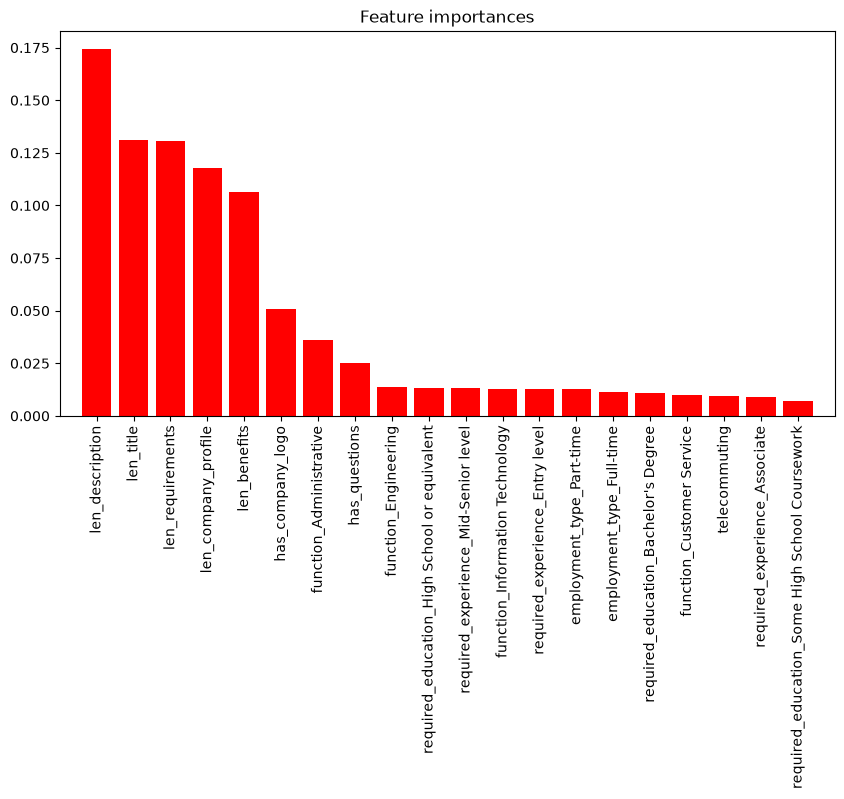

In [78]:
d_first = 20
plt.figure(figsize = (10, 5))
plt.title("Feature importances")
plt.bar(range(d_first), importances[indices[:d_first]], align = 'center', color = 'r')
plt.xticks(range(d_first), feature_names[indices[:d_first]], rotation = 90)
plt.xlim([-1, d_first])
pass

### Extremely Randomized Trees

In [79]:
ert = ensemble.ExtraTreesClassifier(n_estimators = 100, random_state = 42).fit(X_train, y_train)

err_train = np.mean(y_train != ert.predict(X_train))
err_test  = np.mean(y_test  != ert.predict(X_test))
print(err_train, err_test)
print(confusion_matrix(y_test, ert.predict(X_test)))
results['Extra Trees'] = [err_train, err_test, confusion_matrix(y_test, ert.predict(X_test))[1, 1]]

0.0 0.026845637583892617
[[5083   21]
 [ 123  137]]


### AdaBoost

In [80]:
ada = ensemble.AdaBoostClassifier(n_estimators = 1000, random_state = 42)
ada.fit(X_train, y_train)

err_train = np.mean(y_train != ada.predict(X_train))
err_test  = np.mean(y_test  != ada.predict(X_test))
print(err_train, err_test)
print(confusion_matrix(y_test, ada.predict(X_test)))
results['AdaBoost'] = [err_train, err_test, confusion_matrix(y_test, ada.predict(X_test))[1, 1]]

0.04584054744826449 0.04548844146159582
[[5092   12]
 [ 232   28]]


### GBT

In [81]:
gbt = ensemble.GradientBoostingClassifier(n_estimators = 1000, random_state = 42)
gbt.fit(X_train, y_train)

err_train = np.mean(y_train != gbt.predict(X_train))
err_test  = np.mean(y_test  != gbt.predict(X_test))
print(err_train, err_test)
print(confusion_matrix(y_test, gbt.predict(X_test)))
results['GBT'] = [err_train, err_test, confusion_matrix(y_test, gbt.predict(X_test))[1, 1]]

0.005441503833786792 0.024608501118568233
[[5078   26]
 [ 106  154]]


### Сравнение

In [82]:
print('Всего мошеннических вакансий в тестовой выборке:', y_test.sum())
pd.DataFrame(results, index = ['err_train', 'err_test', 'найдено мошеннических']).T \
    .astype({'найдено мошеннических': int})

Всего мошеннических вакансий в тестовой выборке: 260


,err_train,err_test,найдено мошеннических
"kNN, k = 2",0.018303,0.032438,116
SVC,0.047654,0.048471,0
Random Forest,0.000000,0.026473,127
Extra Trees,0.000000,0.026846,137
AdaBoost,0.045841,0.045488,28
GBT,0.005442,0.024609,154


- Лучший результат у градиентного бустинга (GBT): ошибка на тестовой выборке 2.5%, найдено 154 мошеннические
  вакансии из 260 (59%). Близки к нему Random Forest (2.6%, найдено 127) и Extra Trees (2.7%, найдено 137).
  У них ошибка на обучающей выборке равна нулю: деревья запоминают обучающую выборку, но на тестовой всё равно
  работают лучше $k$NN.
- kNN (k = 2) немного хуже: ошибка 3.2%, найдено 116.
- SVC (`gamma = 'auto'`) отнёс все вакансии к настоящим: его ошибка 4.8% совпадает
  с ошибкой классификатора, который всегда отвечает 0, и ни одной мошеннической вакансии он не нашёл.
- AdaBoost тоже почти не находит мошеннические вакансии (28 из 260), его ошибка 4.5% лишь немного меньше 4.8%.
- По значимости признаков (Random Forest) важнее всего длины текстов, затем наличие логотипа компании,
  направление работы Administrative и наличие вопросов к кандидату.

## 13. Выводы

1. Решалась задача бинарной классификации: определить по описанию вакансии, является ли она мошеннической.
   Классы сильно несбалансированы - мошеннических вакансий 4.8%.
2. Тексты вакансий заменены их длинами, столбцы со слишком большим числом значений удалены. Выбросы в длинах удалены
   из обучающей выборки по квантилям 0.005 и 0.995, пропуски в категориальных признаках заполнены самым частым
   значением, категориальные признаки бинаризованы, числовые нормализованы.
3. Связь отдельных признаков с целевой переменной слабая. Сильнее всего с мошенничеством связаны отсутствие логотипа
   и описания компании и отсутствие вопросов к кандидату.
4. Для метода ближайших соседей оптимальное число соседей k = 2 (по перекрёстной проверке). Ошибка на тестовой
   выборке 3.2%, найдено 45% мошеннических вакансий.
5. Лучший из рассмотренных классификаторов - градиентный бустинг: ошибка 2.5%, найдено 59% мошеннических вакансий.
   Random Forest и Extra Trees немного хуже, SVC и AdaBoost почти не находят мошеннические вакансии.
6. Из-за несбалансированности классов доля ошибок плохо отражает качество: классификатор, который вообще не находит
   мошеннические вакансии, ошибается всего в 4.8% случаев. Поэтому обязательно нужно смотреть на матрицу
   рассогласования.